# Model Comparison

CRISP-DM phase: Evaluation

## 1. Setup and Data Loading

### 1.1 Importing Libraries

In [1]:
#necessary imports
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score, precision_score

### 1.2 Loading the Data and the Saved Models

The four models are the final versions saved by their own notebooks. All four were trained on the same `train.csv` and tuned on `recall_macro`, and they are compared here on the same `test.csv`, which none of them used for tuning.

In [2]:
#loading the saved training and test sets
train = pd.read_csv('../data/train.csv')
test = pd.read_csv('../data/test.csv')

In [3]:
#separating the features (X) from the level (y)
X_train = train.drop('level', axis=1)
y_train = train['level']
X_test = test.drop('level', axis=1)
y_test = test['level']

In [4]:
#loading the four saved models
model_lr = joblib.load('../models/logistic_regression_model.pkl')
model_dt = joblib.load('../models/decision_tree_model.pkl')
model_rf = joblib.load('../models/random_forest_model.pkl')
model_xgb = joblib.load('../models/xgboost_model.pkl')

In [5]:
#predicting the test set with each model
y_pred_lr = model_lr.predict(X_test)
y_pred_dt = model_dt.predict(X_test)
y_pred_rf = model_rf.predict(X_test)
y_pred_xgb = model_xgb.predict(X_test)

## 2. Overall Results on the Test Set

### 2.1 Macro Recall and Accuracy

In [6]:
#macro recall (the tuning metric) and accuracy of the four models
overall = pd.DataFrame({'model': ['Logistic regression', 'Decision tree', 'Random forest', 'XGBoost'],
                        'macro recall': [recall_score(y_test, y_pred_lr, average='macro'), recall_score(y_test, y_pred_dt, average='macro'), recall_score(y_test, y_pred_rf, average='macro'), recall_score(y_test, y_pred_xgb, average='macro')],
                        'accuracy': [accuracy_score(y_test, y_pred_lr), accuracy_score(y_test, y_pred_dt), accuracy_score(y_test, y_pred_rf), accuracy_score(y_test, y_pred_xgb)]})
overall.round(3)

,model,macro recall,accuracy
0,Logistic regression,0.783,0.798
1,Decision tree,0.759,0.773
2,Random forest,0.774,0.784
3,XGBoost,0.779,0.801


### 2.2 Recall for Each Level

In [7]:
#recall for each level (0 = okay, 1 = mild, 2 = moderate or worse)
by_level = pd.DataFrame({'model': ['Logistic regression', 'Decision tree', 'Random forest', 'XGBoost'],
                         'okay recall': [recall_score(y_test, y_pred_lr, average=None)[0], recall_score(y_test, y_pred_dt, average=None)[0], recall_score(y_test, y_pred_rf, average=None)[0], recall_score(y_test, y_pred_xgb, average=None)[0]],
                         'mild recall': [recall_score(y_test, y_pred_lr, average=None)[1], recall_score(y_test, y_pred_dt, average=None)[1], recall_score(y_test, y_pred_rf, average=None)[1], recall_score(y_test, y_pred_xgb, average=None)[1]],
                         'level 2 recall': [recall_score(y_test, y_pred_lr, average=None)[2], recall_score(y_test, y_pred_dt, average=None)[2], recall_score(y_test, y_pred_rf, average=None)[2], recall_score(y_test, y_pred_xgb, average=None)[2]]})
by_level.round(3)

,model,okay recall,mild recall,level 2 recall
0,Logistic regression,0.832,0.734,0.782
1,Decision tree,0.763,0.809,0.704
2,Random forest,0.817,0.718,0.786
3,XGBoost,0.832,0.747,0.759


#### Observation

Logistic regression has the highest macro recall on the test set (0.783), followed by XGBoost (0.779), random forest (0.774) and the decision tree (0.759). The first three are within 0.01 of each other, and the decision tree is about 0.02 below the best. Accuracy is between 77% and 80% for all four models, with XGBoost (0.801) and logistic regression (0.798) the highest, but accuracy hides the differences between levels.

For level 2, random forest (78.6%) and logistic regression (78.2%) are almost the same, XGBoost finds 75.9% and the decision tree 70.4%. Logistic regression and XGBoost both find 83% of okay students, random forest 82% and the decision tree only 76%. The decision tree has the highest recall for mild students (81%), but it gets there by predicting mild too often, which costs it okay recall.

## 3. The Moderate or Worse Class (Level 2)

Finding level 2 students is the main aim, because a missed student gets no counselor referral. In the app, a student predicted level 2 is asked to see a counselor, a student predicted mild gets resources, and a student predicted okay gets a short message.

### 3.1 Confusion Matrices

In [8]:
#confusion matrix of each model on the test set (rows = true level, columns = predicted level)
cm_lr = confusion_matrix(y_test, y_pred_lr)
cm_dt = confusion_matrix(y_test, y_pred_dt)
cm_rf = confusion_matrix(y_test, y_pred_rf)
cm_xgb = confusion_matrix(y_test, y_pred_xgb)

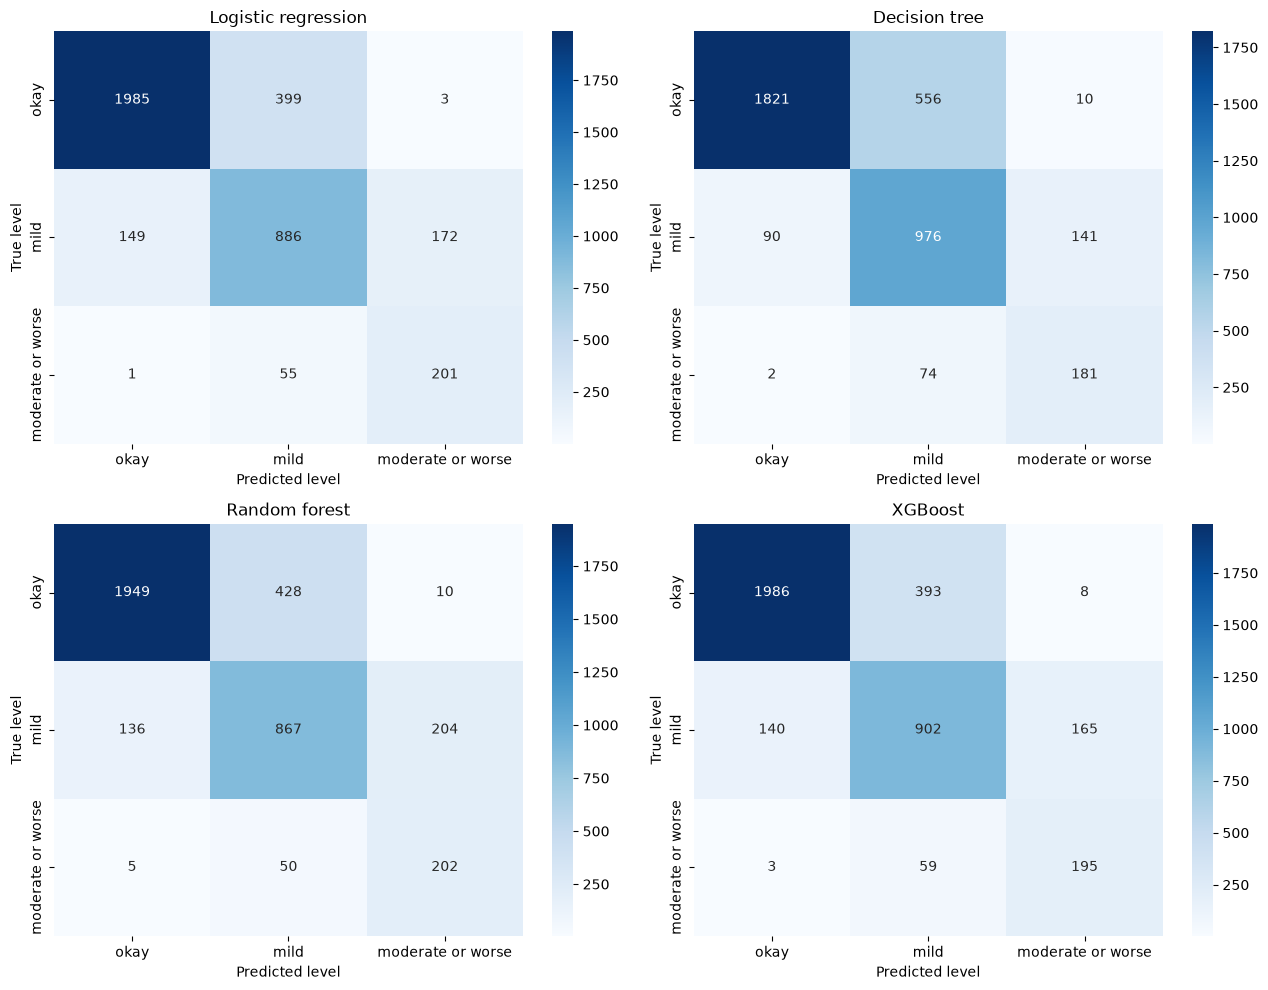

In [9]:
#drawing the four confusion matrices
level_names = ['okay', 'mild', 'moderate or worse']
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', xticklabels=level_names, yticklabels=level_names, ax=axes[0, 0])
axes[0, 0].set_title('Logistic regression')
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues', xticklabels=level_names, yticklabels=level_names, ax=axes[0, 1])
axes[0, 1].set_title('Decision tree')
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', xticklabels=level_names, yticklabels=level_names, ax=axes[1, 0])
axes[1, 0].set_title('Random forest')
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Blues', xticklabels=level_names, yticklabels=level_names, ax=axes[1, 1])
axes[1, 1].set_title('XGBoost')
for ax in axes.flatten():
    ax.set_xlabel('Predicted level')
    ax.set_ylabel('True level')
plt.tight_layout()
plt.show()

### 3.2 Finding Level 2 Students

In [10]:
#how many level 2 students each model finds, and how many students it flags as level 2
level2 = pd.DataFrame({'model': ['Logistic regression', 'Decision tree', 'Random forest', 'XGBoost'],
                       'level 2 found': [cm_lr[2, 2], cm_dt[2, 2], cm_rf[2, 2], cm_xgb[2, 2]],
                       'level 2 missed': [cm_lr[2, :2].sum(), cm_dt[2, :2].sum(), cm_rf[2, :2].sum(), cm_xgb[2, :2].sum()],
                       'level 2 recall': [cm_lr[2, 2] / cm_lr[2].sum(), cm_dt[2, 2] / cm_dt[2].sum(), cm_rf[2, 2] / cm_rf[2].sum(), cm_xgb[2, 2] / cm_xgb[2].sum()],
                       'level 2 precision': [precision_score(y_test == 2, y_pred_lr == 2), precision_score(y_test == 2, y_pred_dt == 2), precision_score(y_test == 2, y_pred_rf == 2), precision_score(y_test == 2, y_pred_xgb == 2)],
                       'students flagged': [cm_lr[:, 2].sum(), cm_dt[:, 2].sum(), cm_rf[:, 2].sum(), cm_xgb[:, 2].sum()]})
level2['share flagged'] = level2['students flagged'] / len(y_test)
level2.round(3)

,model,level 2 found,level 2 missed,level 2 recall,level 2 precision,students flagged,share flagged
0,Logistic regression,201,56,0.782,0.535,376,0.098
1,Decision tree,181,76,0.704,0.545,332,0.086
2,Random forest,202,55,0.786,0.486,416,0.108
3,XGBoost,195,62,0.759,0.530,368,0.096


In [11]:
#share of the test students who really are level 2
print(round((y_test == 2).mean(), 3))

0.067


#### Observation

Random forest finds the most level 2 students (202 of 257), followed by logistic regression (201), XGBoost (195) and the decision tree (181). Logistic regression and random forest differ by one student, which is far too small to separate them.

Every model flags more students as level 2 than there really are. Only 6.7% of the test students are level 2, but the models flag between 8.6% (decision tree, 332 students) and 10.8% (random forest, 416 students). Logistic regression flags 376 (9.8%) and XGBoost 368 (9.6%). Random forest flags about 40 more students than logistic regression to find one more level 2 student. The precision of level 2 is about 53% for logistic regression, XGBoost and the decision tree and 49% for random forest, so in the app about half of the students sent to a counselor would not be level 2 students. This is the price of the class weights that raised level 2 recall.

### 3.3 Where the Mistakes Go

In [12]:
#what happens to the level 2 students who are missed, and where the false alarms come from
mistakes = pd.DataFrame({'model': ['Logistic regression', 'Decision tree', 'Random forest', 'XGBoost'],
                         'level 2 predicted okay': [cm_lr[2, 0], cm_dt[2, 0], cm_rf[2, 0], cm_xgb[2, 0]],
                         'level 2 predicted mild': [cm_lr[2, 1], cm_dt[2, 1], cm_rf[2, 1], cm_xgb[2, 1]],
                         'okay predicted level 2': [cm_lr[0, 2], cm_dt[0, 2], cm_rf[0, 2], cm_xgb[0, 2]],
                         'mild predicted level 2': [cm_lr[1, 2], cm_dt[1, 2], cm_rf[1, 2], cm_xgb[1, 2]]})
mistakes['two levels away'] = mistakes['level 2 predicted okay'] + mistakes['okay predicted level 2']
mistakes

,model,level 2 predicted okay,level 2 predicted mild,okay predicted level 2,mild predicted level 2,two levels away
0,Logistic regression,1,55,3,172,4
1,Decision tree,2,74,10,141,12
2,Random forest,5,50,10,204,15
3,XGBoost,3,59,8,165,11


#### Observation

Almost all missed level 2 students are predicted mild and not okay: 55 of 56 for logistic regression, 74 of 76 for the decision tree, 50 of 55 for random forest and 59 of 62 for XGBoost. In the app, a student predicted mild gets resources but no counselor referral, so these students are the ones the app fails to refer. The boundary between mild and moderate or worse is the hardest one for every model.

The students predicted okay who are really level 2 are the most worrying mistakes, because they would be told they are fine. There are 1 for logistic regression, 2 for the decision tree, 3 for XGBoost and 5 for random forest. These numbers are small, so the differences between the models could be chance. Logistic regression also has the fewest mistakes that are two levels away (4, against 11 for XGBoost, 12 for the decision tree and 15 for random forest). Most false alarms for level 2 are mild students: 172 of 175 for logistic regression, 165 of 173 for XGBoost, 141 of 151 for the decision tree and 204 of 214 for random forest.

## 4. How Sure Can We Be?

The test set has only 257 level 2 students, so each model's level 2 recall could change by a few points with a different sample of students. To measure this, the test students are resampled 1,000 times with replacement (bootstrap), and the level 2 recall is calculated again on each resample. The same resamples are used for all four models, so the differences between models can be compared fairly. This only measures the effect of having a small test set, not the effect of training the models differently.

In [13]:
#1,000 random resamples of the test students (the same resamples for every model)
rng = np.random.default_rng(42)
idx = rng.integers(0, len(y_test), size=(1000, len(y_test)))
is_level2 = (y_test == 2).to_numpy()

In [14]:
#level 2 recall of each model in each of the 1,000 resamples
boot_lr = ((y_pred_lr == 2) & is_level2)[idx].sum(axis=1) / is_level2[idx].sum(axis=1)
boot_dt = ((y_pred_dt == 2) & is_level2)[idx].sum(axis=1) / is_level2[idx].sum(axis=1)
boot_rf = ((y_pred_rf == 2) & is_level2)[idx].sum(axis=1) / is_level2[idx].sum(axis=1)
boot_xgb = ((y_pred_xgb == 2) & is_level2)[idx].sum(axis=1) / is_level2[idx].sum(axis=1)

In [15]:
#95% range of the level 2 recall of each model
ranges = pd.DataFrame({'model': ['Logistic regression', 'Decision tree', 'Random forest', 'XGBoost'],
                       'level 2 recall': [boot_lr.mean(), boot_dt.mean(), boot_rf.mean(), boot_xgb.mean()],
                       'lower 95%': [np.percentile(boot_lr, 2.5), np.percentile(boot_dt, 2.5), np.percentile(boot_rf, 2.5), np.percentile(boot_xgb, 2.5)],
                       'upper 95%': [np.percentile(boot_lr, 97.5), np.percentile(boot_dt, 97.5), np.percentile(boot_rf, 97.5), np.percentile(boot_xgb, 97.5)]})
ranges.round(3)

,model,level 2 recall,lower 95%,upper 95%
0,Logistic regression,0.783,0.735,0.830
1,Decision tree,0.706,0.648,0.760
2,Random forest,0.786,0.740,0.833
3,XGBoost,0.760,0.706,0.808


In [16]:
#difference in level 2 recall between logistic regression and each other model (positive = logistic regression is higher)
differences = pd.DataFrame({'compared with': ['Decision tree', 'Random forest', 'XGBoost'],
                            'mean difference': [(boot_lr - boot_dt).mean(), (boot_lr - boot_rf).mean(), (boot_lr - boot_xgb).mean()],
                            'lower 95%': [np.percentile(boot_lr - boot_dt, 2.5), np.percentile(boot_lr - boot_rf, 2.5), np.percentile(boot_lr - boot_xgb, 2.5)],
                            'upper 95%': [np.percentile(boot_lr - boot_dt, 97.5), np.percentile(boot_lr - boot_rf, 97.5), np.percentile(boot_lr - boot_xgb, 97.5)]})
differences.round(3)

,compared with,mean difference,lower 95%,upper 95%
0,Decision tree,0.077,0.040,0.117
1,Random forest,-0.004,-0.033,0.027
2,XGBoost,0.023,-0.004,0.052


#### Observation

The 95% ranges for level 2 recall are about 5 points on each side of the test score: 73.5% to 83.0% for logistic regression, 74.0% to 83.3% for random forest, 70.6% to 80.8% for XGBoost and 64.8% to 76.0% for the decision tree. The first three overlap almost completely.

Compared with random forest, logistic regression is 0.4 points lower on average, with a 95% range of -3.3 to +2.7 points. Compared with XGBoost it is 2.3 points higher, with a range of -0.4 to +5.2 points. Both ranges include zero, so with this test set we cannot say that these three models differ in level 2 recall. For the decision tree the difference is 7.7 points (range +4.0 to +11.7) and does not include zero, so the decision tree is clearly worse at finding level 2 students than logistic regression. These ranges only show the effect of the small test set (257 level 2 students). They do not show how much the models would change if they were trained on different students.

## 5. Cross-Validation Check

The test set is small, so the cross-validation score on the training set is a second opinion. The next cells repeat the 5-fold cross-validation with the same folds as in the model notebooks, using the final settings of each model. XGBoost is given the same balanced sample weights as in its own notebook.

In [17]:
#same cross-validation folds as in the model notebooks, and the sample weights for xgboost
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
sample_weight = compute_sample_weight('balanced', y_train)

In [18]:
#cross-validation recall_macro of each final model
scores_lr = cross_val_score(clone(model_lr), X_train, y_train, cv=cv, scoring='recall_macro')
scores_dt = cross_val_score(clone(model_dt), X_train, y_train, cv=cv, scoring='recall_macro')
scores_rf = cross_val_score(clone(model_rf), X_train, y_train, cv=cv, scoring='recall_macro')
scores_xgb = cross_val_score(clone(model_xgb), X_train, y_train, cv=cv, scoring='recall_macro', params={'sample_weight': sample_weight})

In [19]:
#cross-validation score next to the test score
cv_results = pd.DataFrame({'model': ['Logistic regression', 'Decision tree', 'Random forest', 'XGBoost'],
                          'cv mean recall_macro': [scores_lr.mean(), scores_dt.mean(), scores_rf.mean(), scores_xgb.mean()],
                          'cv std': [scores_lr.std(), scores_dt.std(), scores_rf.std(), scores_xgb.std()],
                          'test macro recall': overall['macro recall']})
cv_results.round(4)

,model,cv mean recall_macro,cv std,test macro recall
0,Logistic regression,0.7893,0.0122,0.7826
1,Decision tree,0.7573,0.0103,0.7586
2,Random forest,0.7831,0.0072,0.7736
3,XGBoost,0.7915,0.0107,0.7794


#### Observation

The cross-validation scores give the same picture as the test set. XGBoost (0.7915), logistic regression (0.7893) and random forest (0.7831) are within 0.01 of each other, which is about the size of the standard deviation between folds (0.007 to 0.012), and the decision tree is lower (0.7573). The test scores are 0.007 to 0.012 below the cross-validation scores for logistic regression, XGBoost and random forest, and the same for the decision tree (+0.001). A small drop is expected for models that were tuned on those same folds, because the best of many settings tends to look a little better than it is. The drop is largest for XGBoost (0.012), which had the biggest search, and smallest for logistic regression (0.007), which fits that explanation, but the differences are small.

XGBoost's cross-validation score here (0.7915) is slightly lower than the 0.793 in its own notebook. We did not investigate the 0.002 difference, and it is far smaller than the variation between folds.

## 6. Size and Speed in the App

The app will run the model on the phone for one student at a time, so what matters is how much the model has to calculate for one prediction. The `.pkl` files are only for Python, and the app needs its own export of the model, so the file sizes below are just a rough guide to how big each model is.

In [20]:
#size of each model and the most steps it needs for one student
size = pd.DataFrame({'model': ['Logistic regression', 'Decision tree', 'Random forest', 'XGBoost'],
                     'saved file (KB)': [os.path.getsize('../models/logistic_regression_model.pkl') / 1024, os.path.getsize('../models/decision_tree_model.pkl') / 1024, os.path.getsize('../models/random_forest_model.pkl') / 1024, os.path.getsize('../models/xgboost_model.pkl') / 1024],
                     'most steps per student': [model_lr.coef_.size, model_dt.get_depth(), model_rf.n_estimators * model_rf.max_depth, model_xgb.n_estimators * 3 * model_xgb.max_depth]})
size.round(1)

,model,saved file (KB),most steps per student
0,Logistic regression,1.8,63
1,Decision tree,7.1,5
2,Random forest,410.1,250
3,XGBoost,174.4,450


#### Observation

For one student, logistic regression needs 63 multiplications (21 answers for each of the 3 levels), the decision tree at most 5 comparisons, random forest at most 250 (50 trees with 5 questions each) and XGBoost at most 450 (150 trees with 3 questions each). All of these are very small amounts of work for a phone, so we expect every model to answer well within a fraction of a second. We have not timed them on a phone, and speed does not separate the models.

The difference is in what the app has to carry. Logistic regression is 66 numbers (63 weights and 3 intercepts) with no library, and its result can be checked against Python exactly. The decision tree is 32 leaves. Random forest (up to about 1,500 leaves) and XGBoost (up to about 1,200 leaves) must be exported from Python and read by extra code in the app, which is more to build and to test.

## 7. Decision

- **Chosen model for the app:** logistic regression with `class_weight='balanced'` and `C = 1`, running fully on the phone.
- **Level 2 recall:** logistic regression, random forest and XGBoost cannot be told apart on level 2 recall with this test set (differences of 0.4 and 2.3 points, and both 95% ranges include zero). The decision tree is clearly lower (7.7 points).
- **Dangerous mistakes:** logistic regression has the fewest level 2 students predicted okay (1, against 2 to 5) and the fewest mistakes two levels away (4, against 11 to 15). These counts are small, so they support the choice but do not prove it.
- **Counselor workload:** it flags 9.8% of students as level 2, about the same as XGBoost (9.6%) and fewer than random forest (10.8%), which finds only one more level 2 student for about 40 more flags.
- **Agreement between cross-validation and test:** 0.789 and 0.783, a gap of 0.007.
- **Speed, privacy and simplicity:** 63 multiplications and 66 numbers per prediction, no library, nothing sent to a server, and the Kotlin version can be checked against Python on every test student. Random forest and XGBoost add an export and extra code for no measurable gain.
- **What we give up:** XGBoost has a slightly higher cross-validation score (0.7915 against 0.7893), but the difference is smaller than the variation between folds. The decision tree is the easiest to read, but it misses the most level 2 students.
- **How the app uses the model:** predicted okay gets a short message with optional resources, predicted mild gets in-app resources (with an easy way to contact a counselor), and predicted moderate or worse is asked to see a counselor as soon as possible, with support resources for the wait.
- **Limits:** the test set has only 257 level 2 students, all students come from one dataset and app users may differ, the questions were selected using all students before the split, and about half of the students sent to a counselor are false alarms. The model never sees PHQ-9 question 9 (thoughts of self-harm), so a student predicted okay could still be at risk. The app should ask that question directly, outside the model, and its handling should be agreed with the counselor.

The next notebook, `ExportToAndroid.ipynb`, exports the logistic regression model as a Kotlin file and creates test cases that check the app gives the same answers as Python.